# Taller Olist. Módulo A: clasificación de entregas tardías

Pregunta de negocio: en el momento en que se aprueba una orden, ¿cuál es la probabilidad de que llegue después de la fecha estimada de entrega?

El notebook parte de la limpieza definida en el Módulo 0 (archivos `00_20` a `00_23` de la carpeta `sql`), construye las variables en SQL, compara varios modelos con validación temporal, escoge el umbral con una matriz de costos, revisa la calibración y al final evalúa una sola vez en el conjunto de prueba.

## 1. Configuración

In [1]:
import subprocess
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import duckdb
import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline as PipelineSk
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Rutas relativas a la raíz del repositorio
RAIZ = Path.cwd() if (Path.cwd() / "sql").exists() else Path.cwd().parent
RUTA_SQL = RAIZ / "sql"
RUTA_DB = RAIZ / "data" / "olist.duckdb"
RUTA_SCRIPT = RAIZ / "scripts" / "build_olist_duckdb.py"

SEED = 42

# Período útil definido en el Módulo 0 (el fin es excluyente)
PERIODO_INICIO = "2017-01-01"
PERIODO_FIN = "2018-08-22"

# Partición temporal fija del taller, por fecha de compra (los fines son excluyentes)
INICIO_TRAIN = "2017-01-01"
INICIO_VAL = "2018-04-01"
INICIO_TEST = "2018-06-01"
FIN_TEST = "2018-08-16"

# Parámetros de las variables
SUAVIZADO_M = 10          # peso de la tasa global al suavizar las tasas históricas
VENTANA_GLOBAL_DIAS = 14  # ventana para la tasa de retraso reciente de toda la operación
VENTANA_ESTADO_DIAS = 30  # ventana para la tasa de retraso reciente del estado del cliente

# Matriz de costos (en unidades de costo de una intervención)
COSTO_INTERVENCION = 1    # avisar al cliente y priorizar la orden
COSTO_NO_AVISAR = 5       # retraso que llega sin aviso

print(f"Raíz del proyecto: {RAIZ}")

Raíz del proyecto: /tmp/claude-0/-home-claude/8313014f-d9d7-5674-bd85-3a9acf337149/scratchpad/taller


In [2]:
# Estilo de los gráficos
AZUL = "#2a78d6"
NARANJA = "#eb6834"
VERDE = "#1baf7a"
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4), "font.size": 10,
    "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e4e2",
    "legend.frameon": False, "lines.linewidth": 1.6,
})

Funciones de apoyo. Las tres primeras son las mismas del Módulo 0 para conectarse a la base y correr los archivos SQL. Las demás arman los pipelines y calculan métricas y costos.

In [3]:
def conectar(ruta_db=RUTA_DB):
    """Abre la base en solo lectura. Si no existe, la construye con el script del curso."""
    if not ruta_db.exists():
        subprocess.run([sys.executable, str(RUTA_SCRIPT), "--out", str(ruta_db)], check=True)
    return duckdb.connect(str(ruta_db), read_only=True)


def leer_sql(nombre):
    return (RUTA_SQL / f"{nombre}.sql").read_text(encoding="utf-8")


def consulta(nombre, params=None):
    """Ejecuta un archivo SQL que devuelve filas y lo entrega como DataFrame."""
    return con.execute(leer_sql(nombre), params or []).df()


def ejecutar(nombre, params=None):
    """Ejecuta un archivo SQL que crea una tabla temporal."""
    inicio = time.time()
    con.execute(leer_sql(nombre), params or [])
    print(f"{nombre} listo en {time.time() - inicio:.1f} s")


def crear_pipeline(modelo, balanceo="ninguno"):
    """Preprocesamiento + (submuestreo opcional) + modelo.

    El submuestreo va dentro del pipeline, así que solo se aplica a los datos con los que
    se entrena en cada paso y nunca a validación ni a prueba.
    """
    pasos = [("prep", crear_preprocesamiento())]
    if balanceo == "submuestreo":
        pasos.append(("submuestreo", RandomUnderSampler(random_state=SEED)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def costo_promedio(y, alertas):
    """Costo esperado por orden según la matriz de costos."""
    y = np.asarray(y)
    alertas = np.asarray(alertas).astype(bool)
    n_alertas = alertas.sum()
    no_avisados = ((~alertas) & (y == 1)).sum()
    return (n_alertas * COSTO_INTERVENCION + no_avisados * COSTO_NO_AVISAR) / len(y)


def resumen_metricas(nombre, y, prob, umbral=None):
    """Métricas de ranking y, si se da un umbral, también de la decisión."""
    fila = {"modelo": nombre,
            "pr_auc": average_precision_score(y, prob),
            "roc_auc": roc_auc_score(y, prob),
            "brier": brier_score_loss(y, prob)}
    if umbral is not None:
        alertas = prob >= umbral
        fila.update({"umbral": umbral,
                     "pct_alertas": 100 * alertas.mean(),
                     "precision": precision_score(y, alertas, zero_division=0),
                     "recall": recall_score(y, alertas),
                     "costo_por_orden": costo_promedio(y, alertas)})
    return fila

## 2. Datos del modelo

Primero se recrean las tablas limpias del Módulo 0 con los mismos parámetros. Luego se corren los archivos del Módulo A, cada uno en una tabla temporal:

1. `A_01_poblacion`: órdenes válidas entregadas y con fecha de aprobación, el objetivo y la partición.
2. `A_02_festivos`: festivos nacionales de Brasil, que llegan como parámetro desde la librería holidays.
3. `A_03` a `A_06`: variables de los ítems, del pago, del calendario y del contexto de la operación.
4. `A_07` y `A_08`: históricos del vendedor y de la ruta, calculados sin fuga.
5. `A_09_dataset_modelo`: une todo en una fila por orden.

In [4]:
con = conectar()

# Limpieza del Módulo 0
ejecutar("00_20_geo_prefijo")
ejecutar("00_21_productos_limpios")
ejecutar("00_22_ordenes_marcadas", [PERIODO_INICIO, PERIODO_FIN])
ejecutar("00_23_ordenes_validas")

# Variables del Módulo A
festivos_br = sorted(holidays.Brazil(years=range(2016, 2020)).keys())
ejecutar("A_01_poblacion", [INICIO_TRAIN, INICIO_VAL, INICIO_TEST, FIN_TEST])
ejecutar("A_02_festivos", [festivos_br])
ejecutar("A_03_variables_items")
ejecutar("A_04_variables_pagos")
ejecutar("A_05_variables_calendario")
ejecutar("A_06_contexto_operacion", [VENTANA_GLOBAL_DIAS, VENTANA_ESTADO_DIAS])
ejecutar("A_07_historico_vendedor", [SUAVIZADO_M, SUAVIZADO_M])
ejecutar("A_08_historico_ruta", [SUAVIZADO_M, SUAVIZADO_M])

datos = consulta("A_09_dataset_modelo")
datos["dia_semana"] = datos["dia_semana"].astype(str)
print(datos.shape)
datos.head()

00_20_geo_prefijo listo en 0.2 s
00_21_productos_limpios listo en 0.0 s


00_22_ordenes_marcadas listo en 0.2 s
00_23_ordenes_validas listo en 0.1 s


A_01_poblacion listo en 0.1 s
A_02_festivos listo en 0.0 s


A_03_variables_items listo en 0.3 s
A_04_variables_pagos listo en 0.1 s


A_05_variables_calendario listo en 0.2 s


A_06_contexto_operacion listo en 0.4 s


A_07_historico_vendedor listo en 0.3 s


A_08_historico_ruta listo en 0.3 s


(93977, 36)


,order_id,fecha_compra,particion,tarde,estado_cliente,estado_vendedor,categoria,medio_pago,dias_prometidos,horas_hasta_aprobacion,...,vendedor_n_entregas_previas,vendedor_tasa_retraso,vendedor_dias_entrega_prom,ruta_n_entregas_previas,ruta_tasa_retraso,ruta_dias_entrega_prom,holgura_ruta,entregas_recientes,tasa_retraso_reciente,tasa_retraso_reciente_estado
0,ec7a019261fce44180373d45b442d78f,2017-01-05 11:56:06,train,0,PR,PR,fashion_bags_accessories,credit_card,27,0.233333,...,0,0.0,NaN,0,0.0,NaN,NaN,0,NaN,NaN
1,b95a0a8bd30aece4e94e81f0591249d8,2017-01-05 12:01:20,train,0,PR,PR,auto,boleto,39,39.566667,...,0,0.0,NaN,0,0.0,NaN,NaN,0,NaN,NaN
2,38bcb524e1c38c2c1b60600a80fc8999,2017-01-05 12:06:36,train,0,PR,PR,pet_shop,boleto,39,39.650000,...,0,0.0,NaN,0,0.0,NaN,NaN,0,NaN,NaN
3,7a18a504c1a4b32d883e68de2e1a7db0,2017-01-05 12:09:08,train,0,PR,PR,pet_shop,boleto,39,39.583333,...,0,0.0,NaN,0,0.0,NaN,NaN,0,NaN,NaN
4,6acecf438369055d9243e121045cca74,2017-01-05 12:11:23,train,0,PR,PR,pet_shop,boleto,39,39.550000,...,0,0.0,NaN,0,0.0,NaN,NaN,0,NaN,NaN


In [5]:
resumen_particiones = (
    datos.groupby("particion", sort=False)
    .agg(desde=("fecha_compra", "min"), hasta=("fecha_compra", "max"),
         ordenes=("tarde", "size"), tardias=("tarde", "sum"), pct_tarde=("tarde", "mean"))
    .reindex(["train", "val", "test"])
)
resumen_particiones["pct_tarde"] = (100 * resumen_particiones["pct_tarde"]).round(2)
resumen_particiones

,desde,hasta,ordenes,tardias,pct_tarde
particion,,,,,
train,2017-01-05 11:56:06,2018-03-31 23:54:10,64008,5110,7.98
val,2018-04-01 00:11:32,2018-05-31 23:51:24,13532,749,5.54
test,2018-06-01 00:39:55,2018-08-15 23:42:25,16437,627,3.81


La clase positiva es pequeña y además cambia entre particiones: cerca del 8 % en entrenamiento, 5.5 % en validación y 3.8 % en prueba. En el Módulo 0 se vio de dónde sale esto. Entrenamiento incluye el Black Friday de 2017 y la crisis de febrero y marzo de 2018, validación incluye el paro de camioneros de mayo de 2018, y en prueba los tiempos de entrega bajaron mucho. Además, las órdenes de prueba más cercanas al corte que todavía no se habían entregado no entran (censura). Este cambio va a pesar en todo lo que sigue, así que se retoma al final.

## 3. Variables y por qué están disponibles al aprobar

El modelo se usa justo cuando se aprueba la orden. Por eso no se usa la fecha de entrega al transportador, ni la fecha real de entrega, ni las reseñas. Los históricos solo cuentan órdenes que ya estaban entregadas antes de la aprobación, porque antes de la entrega no se sabe si una orden llegó tarde.

| Variable | Qué mide | Por qué se conoce al aprobar |
|---|---|---|
| dias_prometidos | Días entre la compra y la fecha estimada | La fecha estimada se le muestra al cliente al comprar |
| horas_hasta_aprobacion | Horas entre compra y aprobación | Ambas fechas ya ocurrieron |
| dia_semana, hora_compra | Momento de la compra | Fecha de compra |
| festivos_en_plazo | Festivos entre la compra y la fecha estimada | Calendario oficial, se conoce de antemano |
| ordenes_ultimos_7d | Órdenes compradas en los 7 días previos | Son compras pasadas |
| dias_limite_despacho | Plazo que tiene el vendedor para entregar al transportador | Se fija al crear la orden |
| n_items, n_vendedores, precio_total, flete_total, flete_relativo | Contenido y valor de la orden | Están en la orden |
| peso_total_g, volumen_total_cm3, categoria | Características de los productos | Catálogo de productos |
| distancia_km, misma_uf, estado_cliente, estado_vendedor | Geografía de la ruta | Direcciones del cliente y del vendedor |
| medio_pago, cuotas, n_pagos | Forma de pago | Se define al comprar y se confirma al aprobar |
| vendedor_tasa_retraso, vendedor_n_entregas_previas, vendedor_dias_entrega_prom | Historial del vendedor | Solo órdenes del vendedor entregadas antes de la aprobación |
| ruta_tasa_retraso, ruta_n_entregas_previas, ruta_dias_entrega_prom | Historial de la ruta estado a estado | Solo órdenes de la ruta entregadas antes de la aprobación |
| holgura_ruta | Días prometidos menos lo que suele tardar la ruta | Combina dos variables anteriores |
| tasa_retraso_reciente, tasa_retraso_reciente_estado, entregas_recientes | Cómo viene la operación en los últimos días | Solo entregas que ya ocurrieron |

Las tasas históricas se suavizan hacia la tasa global (también calculada solo con el pasado) para que un vendedor con dos órdenes y una tardía no quede con 50 % de retraso.

El punto más delicado son los históricos. Para comprobar que están bien calculados, se toma una muestra de órdenes y se cuenta de forma directa, con un join simple, cuántas órdenes del vendedor estaban entregadas antes de la aprobación. Esa cuenta tiene que coincidir con la que sale del ASOF JOIN.

In [6]:
consulta("A_10_verificacion_historico")

,ordenes_revisadas,ordenes_que_coinciden
0,300,300.0


In [7]:
# Grupos de variables para el preprocesamiento
VARIABLES_LOG = [  # muy sesgadas: se les aplica log(1 + x)
    "precio_total", "flete_total", "flete_relativo", "peso_total_g", "volumen_total_cm3",
    "distancia_km", "horas_hasta_aprobacion", "dias_limite_despacho",
    "vendedor_n_entregas_previas", "ruta_n_entregas_previas", "entregas_recientes",
]
VARIABLES_NUM = [
    "dias_prometidos", "hora_compra", "festivos_en_plazo", "ordenes_ultimos_7d",
    "n_items", "n_vendedores", "misma_uf", "cuotas", "n_pagos",
    "vendedor_tasa_retraso", "vendedor_dias_entrega_prom",
    "ruta_tasa_retraso", "ruta_dias_entrega_prom", "holgura_ruta",
    "tasa_retraso_reciente", "tasa_retraso_reciente_estado",
]
VARIABLES_CAT = ["estado_cliente", "estado_vendedor", "categoria", "medio_pago", "dia_semana"]
VARIABLES = VARIABLES_LOG + VARIABLES_NUM + VARIABLES_CAT


def crear_preprocesamiento():
    """Imputación, transformación log, escalado y one-hot.

    Las categorías con menos de 100 órdenes en entrenamiento se agrupan en una sola
    para no crear columnas casi vacías.
    """
    log = PipelineSk([("imputar", SimpleImputer(strategy="median")),
                      ("log", FunctionTransformer(np.log1p)),
                      ("escalar", StandardScaler())])
    num = PipelineSk([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                      ("escalar", StandardScaler())])
    cat = PipelineSk([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=100, sparse_output=False))])
    return ColumnTransformer([("log", log, VARIABLES_LOG),
                              ("num", num, VARIABLES_NUM),
                              ("cat", cat, VARIABLES_CAT)])


train = datos[datos["particion"] == "train"].reset_index(drop=True)
val = datos[datos["particion"] == "val"].reset_index(drop=True)
test = datos[datos["particion"] == "test"].reset_index(drop=True)

X_train, y_train = train[VARIABLES], train["tarde"]
X_val, y_val = val[VARIABLES], val["tarde"]
X_test, y_test = test[VARIABLES], test["tarde"]

print(f"Entrenamiento {X_train.shape}, validación {X_val.shape}, prueba {X_test.shape}")

Entrenamiento (64008, 32), validación (13532, 32), prueba (16437, 32)


## 4. Baselines

Se usan dos referencias. La primera es un modelo ingenuo que siempre predice la clase mayoritaria. La segunda es una regla de negocio sencilla: avisar cuando la holgura de la ruta es menor a 5 días, es decir, cuando la fecha prometida apenas cubre lo que suele tardar esa ruta.

In [8]:
ingenuo = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_ingenuo = ingenuo.predict(X_val)
alerta_regla = (val["holgura_ruta"].fillna(np.inf) < 5).to_numpy()

baselines = pd.DataFrame([
    {"modelo": "Ingenuo (nunca avisa)",
     "accuracy": accuracy_score(y_val, pred_ingenuo),
     "precision": precision_score(y_val, pred_ingenuo, zero_division=0),
     "recall": recall_score(y_val, pred_ingenuo),
     "costo_por_orden": costo_promedio(y_val, pred_ingenuo)},
    {"modelo": "Regla: holgura de la ruta < 5 días",
     "accuracy": accuracy_score(y_val, alerta_regla),
     "precision": precision_score(y_val, alerta_regla),
     "recall": recall_score(y_val, alerta_regla),
     "costo_por_orden": costo_promedio(y_val, alerta_regla)},
]).round(3)
baselines

,modelo,accuracy,precision,recall,costo_por_orden
0,Ingenuo (nunca avisa),0.945,0.000,0.000,0.277
1,Regla: holgura de la ruta < 5 días,0.806,0.121,0.402,0.349


El modelo ingenuo tiene una accuracy de casi 95 % en validación sin detectar ni una sola orden tardía. Por eso la accuracy no sirve aquí: con tan pocos positivos, cualquier modelo que nunca avise se ve bien. Las métricas que se usan de ahora en adelante son la PR-AUC, que se enfoca en la clase positiva, y la ROC-AUC. Como referencia, la PR-AUC de un modelo al azar es igual a la proporción de positivos (0.055 en validación).

La regla de negocio sí encuentra retrasos, pero con muchas falsas alarmas, y su costo termina siendo más alto que no avisar nunca.

## 5. Validación cruzada temporal: modelos y balanceo

Se comparan tres familias (regresión logística, Random Forest y LightGBM) con tres formas de manejar el desbalance: no hacer nada, dar más peso a la clase positiva (`class_weight`) y submuestrear la clase negativa dentro del pipeline. La tercera estrategia, mover el umbral, se trabaja en la sección 8.

La validación cruzada usa `TimeSeriesSplit` con 4 particiones sobre entrenamiento ordenado por fecha. Se deja un hueco de 3000 órdenes (unas tres semanas) entre cada bloque de entrenamiento y su bloque de evaluación, porque el objetivo de una orden solo se conoce cuando se entrega y no tendría sentido entrenar con órdenes cuyo resultado todavía no existía. Esta sección tarda unos minutos.

In [9]:
cv_temporal = TimeSeriesSplit(n_splits=4, gap=3000)

for i, (idx_ent, idx_eval) in enumerate(cv_temporal.split(X_train)):
    print(f"Fold {i + 1}: entrena hasta {train['fecha_compra'][idx_ent[-1]]:%Y-%m-%d}, "
          f"evalúa {train['fecha_compra'][idx_eval[0]]:%Y-%m-%d} a {train['fecha_compra'][idx_eval[-1]]:%Y-%m-%d}, "
          f"tardías {100 * y_train[idx_eval].mean():.1f} %")


def modelo_base(familia, balanceo):
    peso = "balanced" if balanceo == "peso" else None
    if familia == "Logística":
        return LogisticRegression(max_iter=3000, class_weight=peso)
    if familia == "Random Forest":
        return RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_features="sqrt",
                                      class_weight=peso, n_jobs=-1, random_state=SEED)
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight=peso,
                          random_state=SEED, deterministic=True, force_row_wise=True,
                          verbose=-1, n_jobs=-1)


def evaluar_cv(pipeline):
    r = cross_validate(pipeline, X_train, y_train, cv=cv_temporal,
                       scoring=["average_precision", "roc_auc"])
    return r["test_average_precision"], r["test_roc_auc"]


filas = []
for familia in ["Logística", "Random Forest", "LightGBM"]:
    for balanceo in ["ninguno", "peso", "submuestreo"]:
        pr, roc = evaluar_cv(crear_pipeline(modelo_base(familia, balanceo), balanceo))
        filas.append({"familia": familia, "balanceo": balanceo,
                      "pr_auc_media": pr.mean(), "pr_auc_desv": pr.std(),
                      "roc_auc_media": roc.mean(), "roc_auc_desv": roc.std()})

comparacion_cv = pd.DataFrame(filas).round(3)
comparacion_cv

Fold 1: entrena hasta 2017-05-23, evalúa 2017-06-19 a 2017-09-26, tardías 3.4 %
Fold 2: entrena hasta 2017-09-05, evalúa 2017-09-26 a 2017-12-03, tardías 9.1 %
Fold 3: entrena hasta 2017-11-24, evalúa 2017-12-03 a 2018-02-04, tardías 6.2 %
Fold 4: entrena hasta 2018-01-22, evalúa 2018-02-04 a 2018-03-31, tardías 17.3 %


,familia,balanceo,pr_auc_media,pr_auc_desv,roc_auc_media,roc_auc_desv
0,Logística,ninguno,0.143,0.102,0.601,0.092
1,Logística,peso,0.131,0.084,0.593,0.077
2,Logística,submuestreo,0.136,0.079,0.616,0.036
3,Random Forest,ninguno,0.165,0.113,0.648,0.049
4,Random Forest,peso,0.167,0.116,0.655,0.049
5,Random Forest,submuestreo,0.161,0.101,0.656,0.043
6,LightGBM,ninguno,0.161,0.114,0.646,0.053
7,LightGBM,peso,0.153,0.107,0.630,0.066
8,LightGBM,submuestreo,0.153,0.096,0.634,0.049


Las diferencias entre estrategias de balanceo son pequeñas y quedan dentro de la variación entre folds. La desviación es grande porque los folds son muy distintos entre sí. El último cae en febrero y marzo de 2018, cuando la tasa de retraso pasó del 15 %, y ahí todos los modelos tienen su mejor PR-AUC simplemente porque hay más positivos. El submuestreo no mejora el ranking y sí distorsiona las probabilidades, lo que luego obliga a recalibrar.

## 6. Optimización de hiperparámetros

Para cada familia se usa Optuna con la misma validación cruzada temporal y se maximiza la PR-AUC promedio. La estrategia de balanceo entra como un hiperparámetro más. El número de intentos es pequeño para que el notebook corra en un tiempo razonable.

In [10]:
def objetivo_logistica(trial):
    balanceo = trial.suggest_categorical("balanceo", ["ninguno", "peso", "submuestreo"])
    modelo = LogisticRegression(C=trial.suggest_float("C", 1e-3, 10, log=True),
                                class_weight="balanced" if balanceo == "peso" else None,
                                max_iter=3000)
    pr, roc = evaluar_cv(crear_pipeline(modelo, balanceo))
    trial.set_user_attr("pr_auc_desv", pr.std())
    trial.set_user_attr("roc_auc_media", roc.mean())
    return pr.mean()


def objetivo_random_forest(trial):
    balanceo = trial.suggest_categorical("balanceo", ["ninguno", "peso", "submuestreo"])
    modelo = RandomForestClassifier(
        n_estimators=100,
        max_depth=trial.suggest_int("max_depth", 4, 16),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 200, log=True),
        max_features=trial.suggest_float("max_features", 0.1, 0.6),
        class_weight="balanced_subsample" if balanceo == "peso" else None,
        n_jobs=-1, random_state=SEED)
    pr, roc = evaluar_cv(crear_pipeline(modelo, balanceo))
    trial.set_user_attr("pr_auc_desv", pr.std())
    trial.set_user_attr("roc_auc_media", roc.mean())
    return pr.mean()


def objetivo_lightgbm(trial):
    balanceo = trial.suggest_categorical("balanceo", ["ninguno", "peso", "submuestreo"])
    modelo = LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 64, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 400, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 50, log=True),
        class_weight="balanced" if balanceo == "peso" else None,
        random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1, n_jobs=-1)
    pr, roc = evaluar_cv(crear_pipeline(modelo, balanceo))
    trial.set_user_attr("pr_auc_desv", pr.std())
    trial.set_user_attr("roc_auc_media", roc.mean())
    return pr.mean()


estudios = {}
for familia, objetivo, intentos in [("Logística", objetivo_logistica, 15),
                                    ("Random Forest", objetivo_random_forest, 6),
                                    ("LightGBM", objetivo_lightgbm, 20)]:
    inicio = time.time()
    estudio = optuna.create_study(direction="maximize",
                                  sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=intentos)
    estudios[familia] = estudio
    print(f"{familia}: {intentos} intentos en {time.time() - inicio:.0f} s")

resumen_optuna = pd.DataFrame([
    {"familia": familia,
     "pr_auc_media": e.best_value,
     "pr_auc_desv": e.best_trial.user_attrs["pr_auc_desv"],
     "roc_auc_media": e.best_trial.user_attrs["roc_auc_media"],
     "mejores_parametros": e.best_params}
    for familia, e in estudios.items()
])
resumen_optuna.round(3)

Logística: 15 intentos en 73 s


Random Forest: 6 intentos en 186 s


LightGBM: 20 intentos en 180 s


,familia,pr_auc_media,pr_auc_desv,roc_auc_media,mejores_parametros
0,Logística,0.163,0.122,0.629,"{'balanceo': 'ninguno', 'C': 0.002508578280454..."
1,Random Forest,0.163,0.109,0.657,"{'balanceo': 'peso', 'max_depth': 10, 'min_sam..."
2,LightGBM,0.184,0.128,0.670,"{'balanceo': 'peso', 'n_estimators': 400, 'lea..."


In [11]:
def modelo_ajustado(familia):
    """Crea el pipeline de una familia con sus mejores hiperparámetros."""
    p = dict(estudios[familia].best_params)
    balanceo = p.pop("balanceo")
    if familia == "Logística":
        modelo = LogisticRegression(**p, max_iter=3000,
                                    class_weight="balanced" if balanceo == "peso" else None)
    elif familia == "Random Forest":
        modelo = RandomForestClassifier(**p, n_estimators=100, n_jobs=-1, random_state=SEED,
                                        class_weight="balanced_subsample" if balanceo == "peso" else None)
    else:
        modelo = LGBMClassifier(**p, subsample_freq=1, random_state=SEED, deterministic=True,
                                force_row_wise=True, verbose=-1, n_jobs=-1,
                                class_weight="balanced" if balanceo == "peso" else None)
    return crear_pipeline(modelo, balanceo)


modelos = {familia: modelo_ajustado(familia).fit(X_train, y_train) for familia in estudios}
print("Modelos entrenados con todo el conjunto de entrenamiento.")

Modelos entrenados con todo el conjunto de entrenamiento.


## 7. Selección del modelo en validación

Cada modelo se entrena con todo el conjunto de entrenamiento y se evalúa en validación (abril y mayo de 2018). Aquí se escoge el modelo.

,modelo,pr_auc,roc_auc,brier,prob_media
0,Logística,0.161,0.780,0.061,0.141
2,LightGBM,0.157,0.762,0.316,0.545
1,Random Forest,0.150,0.740,0.270,0.507


Proporción real de tardías en validación: 0.055


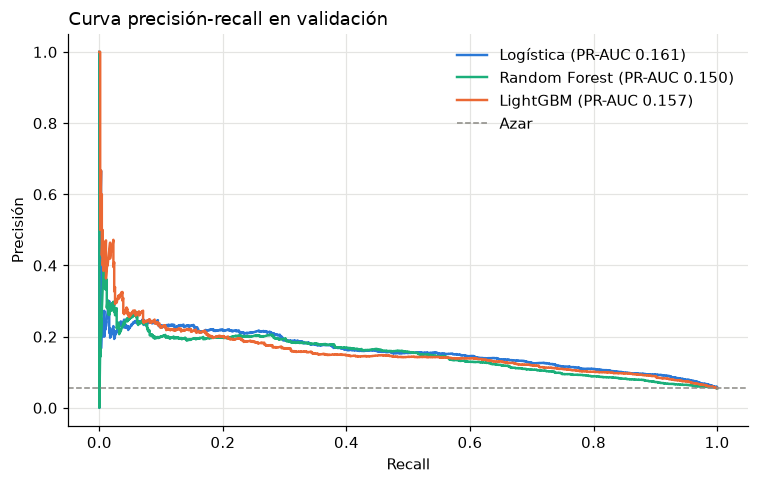

Modelo elegido: Logística


In [12]:
prob_val = {familia: m.predict_proba(X_val)[:, 1] for familia, m in modelos.items()}

seleccion = pd.DataFrame([resumen_metricas(f, y_val, p) for f, p in prob_val.items()])
seleccion["prob_media"] = [p.mean() for p in prob_val.values()]
seleccion = seleccion.sort_values("pr_auc", ascending=False).round(3)
display(seleccion)
print(f"Proporción real de tardías en validación: {y_val.mean():.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for (familia, p), color in zip(prob_val.items(), [AZUL, VERDE, NARANJA]):
    precision, recall, _ = precision_recall_curve(y_val, p)
    ax.plot(recall, precision, color=color,
            label=f"{familia} (PR-AUC {average_precision_score(y_val, p):.3f})")
ax.axhline(y_val.mean(), color=GRIS, linestyle="--", linewidth=1, label="Azar")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title("Curva precisión-recall en validación")
ax.legend()
plt.tight_layout()
plt.show()

MODELO_ELEGIDO = seleccion.iloc[0]["modelo"]
print(f"Modelo elegido: {MODELO_ELEGIDO}")

La regresión logística queda primera en validación en PR-AUC y en ROC-AUC, aunque en la validación cruzada LightGBM había quedado un poco arriba. Es un resultado razonable: los árboles aprenden relaciones más finas del período de entrenamiento y esas relaciones se sostienen peor cuando la operación cambia. La logística, con regularización fuerte, generaliza mejor hacia adelante en el tiempo. Además es más fácil de explicar al negocio. Los dos modelos de árboles quedaron con peso en la clase positiva, y por eso su probabilidad media está alrededor de 0.5 y su Brier es tan alto: ordenan, pero sus probabilidades no se pueden leer como tales.

En todo caso, la PR-AUC queda alrededor de tres veces la de un modelo al azar. El modelo ordena bien las órdenes por riesgo, pero predecir retrasos en el momento de la aprobación es difícil, porque mucho de lo que causa un retraso (problemas del transportador, clima, paros) pasa después.

## 8. Calibración y umbral por costo

### Calibración

Antes de escoger un umbral conviene revisar si las probabilidades significan lo que dicen. En la tabla anterior la probabilidad media del modelo es bastante más alta que la proporción real de tardías en validación, porque el modelo se entrenó con datos que tenían más retrasos. Se recalibra con una regresión logística sobre la salida del modelo (método sigmoid), ajustada en validación.

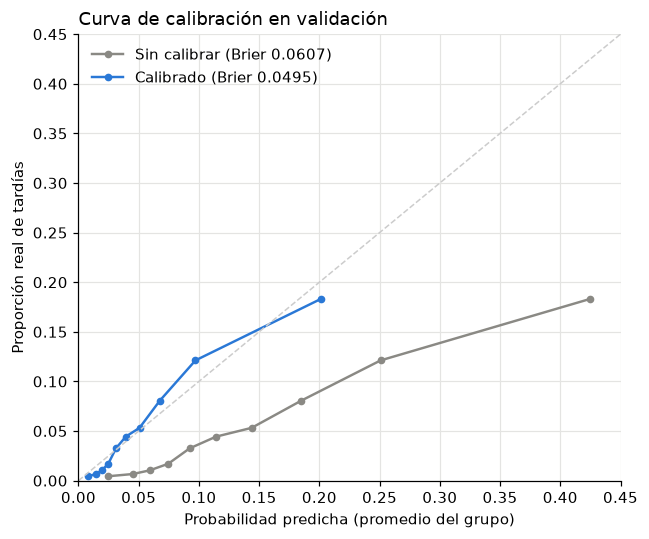

Probabilidad media sin calibrar 0.141, calibrada 0.055, real 0.055


In [13]:
modelo_final = modelos[MODELO_ELEGIDO]
calibrador = CalibratedClassifierCV(FrozenEstimator(modelo_final), method="sigmoid").fit(X_val, y_val)

prob_val_sin = modelo_final.predict_proba(X_val)[:, 1]
prob_val_cal = calibrador.predict_proba(X_val)[:, 1]

fig, ax = plt.subplots(figsize=(6, 5))
for prob, nombre, color in [(prob_val_sin, "Sin calibrar", GRIS), (prob_val_cal, "Calibrado", AZUL)]:
    real, predicho = calibration_curve(y_val, prob, n_bins=10, strategy="quantile")
    ax.plot(predicho, real, marker="o", markersize=4, color=color,
            label=f"{nombre} (Brier {brier_score_loss(y_val, prob):.4f})")
limite = max(prob_val_sin.max(), 0.4)
ax.plot([0, limite], [0, limite], color="#cccccc", linestyle="--", linewidth=1)
ax.set_xlim(0, 0.45)
ax.set_ylim(0, 0.45)
ax.set_xlabel("Probabilidad predicha (promedio del grupo)")
ax.set_ylabel("Proporción real de tardías")
ax.set_title("Curva de calibración en validación")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Probabilidad media sin calibrar {prob_val_sin.mean():.3f}, calibrada {prob_val_cal.mean():.3f}, "
      f"real {y_val.mean():.3f}")

Sin calibrar, el modelo sobreestima el riesgo en casi todos los grupos. Después de calibrar, la curva queda cerca de la diagonal y el Brier baja. Hay un costo: el calibrador y el umbral se ajustan con los mismos datos de validación, así que en validación todo se verá un poco mejor de lo que es. Prueba sigue intacta para medirlo.

### Umbral

La matriz de costos se pensó así. Avisar a un cliente y priorizar su orden cuesta 1 unidad, sea que la orden iba a llegar tarde o no. Un retraso que llega sin aviso cuesta 5 unidades, porque trae reseñas negativas, llamadas al servicio al cliente y clientes que no vuelven.

| | Llega a tiempo | Llega tarde |
|---|---|---|
| No se avisa | 0 | 5 |
| Se avisa | 1 | 1 |

Con probabilidades bien calibradas, avisar conviene cuando 5p > 1, es decir cuando p > 0.2. Además se recorre una grilla de umbrales en validación para ver cuál minimiza el costo promedio.

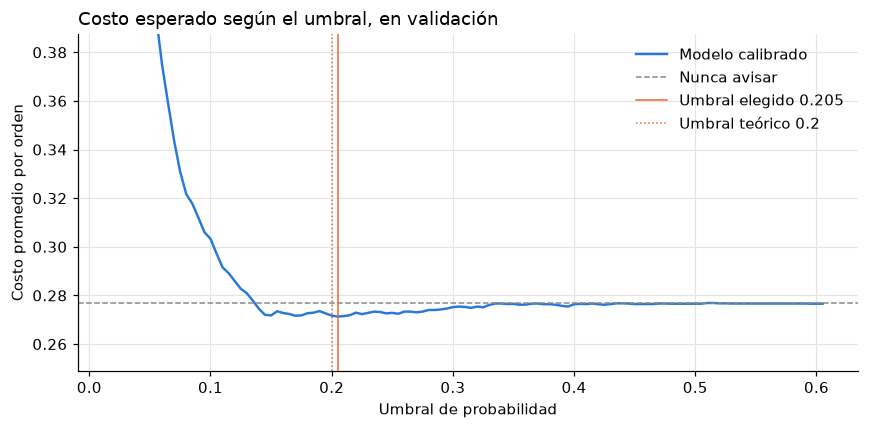

,estrategia,costo_por_orden
0,Nunca avisar,0.2768
1,Regla de holgura,0.3487
2,"Modelo, umbral teórico 0.2",0.2717
3,"Modelo, umbral elegido 0.205",0.2713


In [14]:
umbrales = np.round(np.arange(0.02, 0.61, 0.005), 3)
costos = [costo_promedio(y_val, prob_val_cal >= u) for u in umbrales]
UMBRAL = float(umbrales[int(np.argmin(costos))])
UMBRAL_TEORICO = COSTO_INTERVENCION / COSTO_NO_AVISAR

costo_sin_alertas = costo_promedio(y_val, np.zeros(len(y_val)))
costo_regla = costo_promedio(y_val, alerta_regla)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, costos, color=AZUL, label="Modelo calibrado")
ax.axhline(costo_sin_alertas, color=GRIS, linestyle="--", linewidth=1, label="Nunca avisar")
ax.axvline(UMBRAL, color=NARANJA, linewidth=1, label=f"Umbral elegido {UMBRAL:.3f}")
ax.axvline(UMBRAL_TEORICO, color=NARANJA, linestyle=":", linewidth=1, label="Umbral teórico 0.2")
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Costo promedio por orden")
ax.set_ylim(costo_sin_alertas * 0.9, costo_sin_alertas * 1.4)
ax.set_title("Costo esperado según el umbral, en validación")
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame([
    {"estrategia": "Nunca avisar", "costo_por_orden": costo_sin_alertas},
    {"estrategia": "Regla de holgura", "costo_por_orden": costo_regla},
    {"estrategia": f"Modelo, umbral teórico {UMBRAL_TEORICO}",
     "costo_por_orden": costo_promedio(y_val, prob_val_cal >= UMBRAL_TEORICO)},
    {"estrategia": f"Modelo, umbral elegido {UMBRAL:.3f}",
     "costo_por_orden": costo_promedio(y_val, prob_val_cal >= UMBRAL)},
]).round(4)

El umbral que minimiza el costo en validación queda muy cerca del teórico, lo que confirma que la calibración funcionó. El ahorro frente a no avisar nunca es pequeño. Con esta matriz de costos, una alerta solo se paga si al menos una de cada cinco alertas es un retraso real, y el modelo solo alcanza esa precisión en el grupo de órdenes de mayor riesgo. La regla de negocio sale peor que no hacer nada.

## 9. Evaluación final en prueba

El modelo, el calibrador y el umbral quedan fijos con lo decidido en validación. Prueba (junio a mediados de agosto de 2018) se usa una sola vez.

In [15]:
prob_test = calibrador.predict_proba(X_test)[:, 1]
alerta_regla_test = (test["holgura_ruta"].fillna(np.inf) < 5).to_numpy()

final = pd.DataFrame([resumen_metricas(f"{MODELO_ELEGIDO} calibrada", y_test, prob_test, UMBRAL)])
final["costo_nunca_avisar"] = costo_promedio(y_test, np.zeros(len(y_test)))
final["costo_regla"] = costo_promedio(y_test, alerta_regla_test)
final["pct_tarde_real"] = 100 * y_test.mean()
display(final.round(4).T)

,0
modelo,Logística calibrada
pr_auc,0.0678
roc_auc,0.6733
brier,0.0405
umbral,0.205
pct_alertas,6.1143
precision,0.0806
recall,0.1292
costo_por_orden,0.2272
costo_nunca_avisar,0.1907


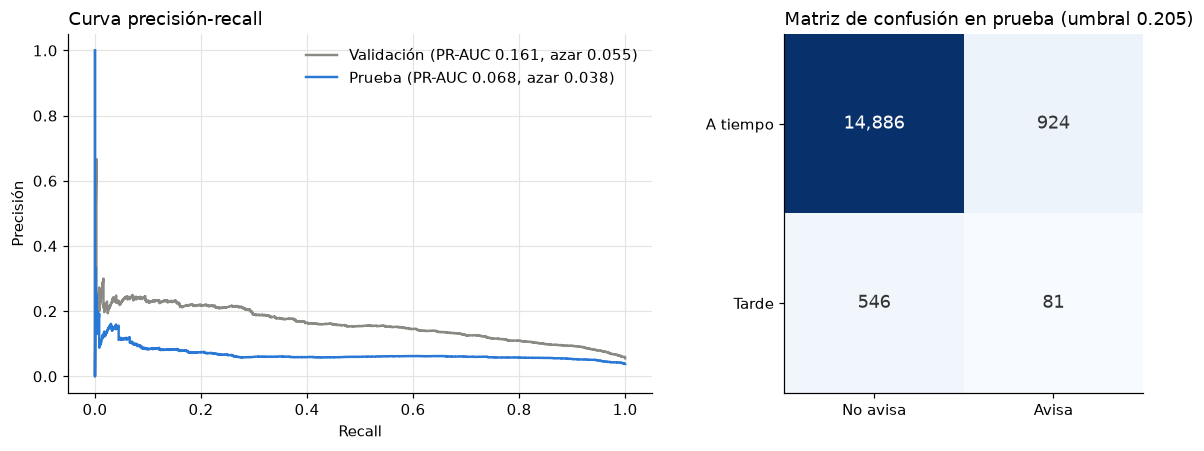

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
for y, p, nombre, color in [(y_val, prob_val_cal, "Validación", GRIS), (y_test, prob_test, "Prueba", AZUL)]:
    precision, recall, _ = precision_recall_curve(y, p)
    ax.plot(recall, precision, color=color,
            label=f"{nombre} (PR-AUC {average_precision_score(y, p):.3f}, azar {y.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title("Curva precisión-recall")
ax.legend()

ax = axes[1]
matriz = confusion_matrix(y_test, prob_test >= UMBRAL)
ax.imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matriz[i, j]:,}", ha="center", va="center",
                color="white" if matriz[i, j] > matriz.max() / 2 else "#333333", fontsize=12)
ax.set_xticks([0, 1], ["No avisa", "Avisa"])
ax.set_yticks([0, 1], ["A tiempo", "Tarde"])
ax.set_title(f"Matriz de confusión en prueba (umbral {UMBRAL:.3f})")
ax.grid(False)
plt.tight_layout()
plt.show()

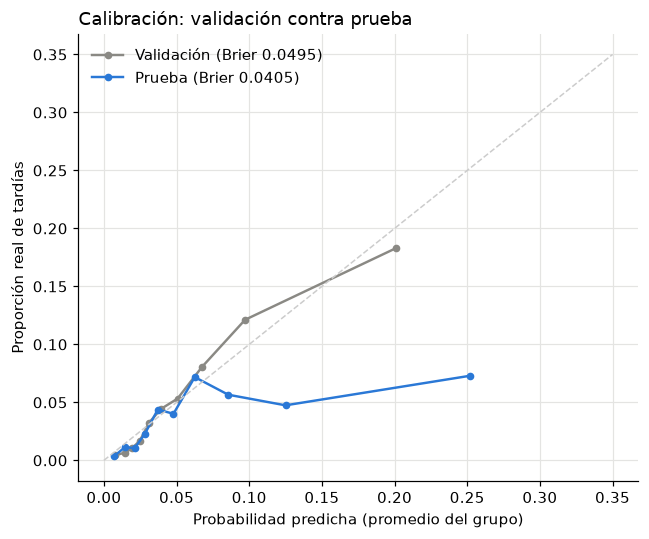

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
for y, p, nombre, color in [(y_val, prob_val_cal, "Validación", GRIS), (y_test, prob_test, "Prueba", AZUL)]:
    real, predicho = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(predicho, real, marker="o", markersize=4, color=color,
            label=f"{nombre} (Brier {brier_score_loss(y, p):.4f})")
ax.plot([0, 0.35], [0, 0.35], color="#cccccc", linestyle="--", linewidth=1)
ax.set_xlabel("Probabilidad predicha (promedio del grupo)")
ax.set_ylabel("Proporción real de tardías")
ax.set_title("Calibración: validación contra prueba")
ax.legend()
plt.tight_layout()
plt.show()

En prueba el desempeño cae. La PR-AUC sigue por encima del azar, pero la ventaja es menor que en validación, y la ROC-AUC también baja. Con el umbral fijado en validación, el modelo genera más alertas de las que convienen y su costo queda por encima de no avisar nunca. La curva de calibración muestra por qué: en prueba el modelo predice más riesgo del que hubo, porque la proporción real de tardías cayó de 5.5 % a 3.8 %.

## 10. Deriva temporal

Para ver el cambio mes a mes se compara la probabilidad media que predice el modelo contra la proporción real de tardías. En validación las dos líneas coinciden, como es de esperar después de calibrar. En prueba el modelo sigue la dirección del retraso, que baja en junio y sube en julio y agosto, pero siempre por encima del valor real.

,real,predicho
mes,,
2018-04-01,4.51,4.42
2018-05-01,6.56,6.65
2018-06-01,1.17,3.47
2018-07-01,3.39,7.13
2018-08-01,8.26,11.19


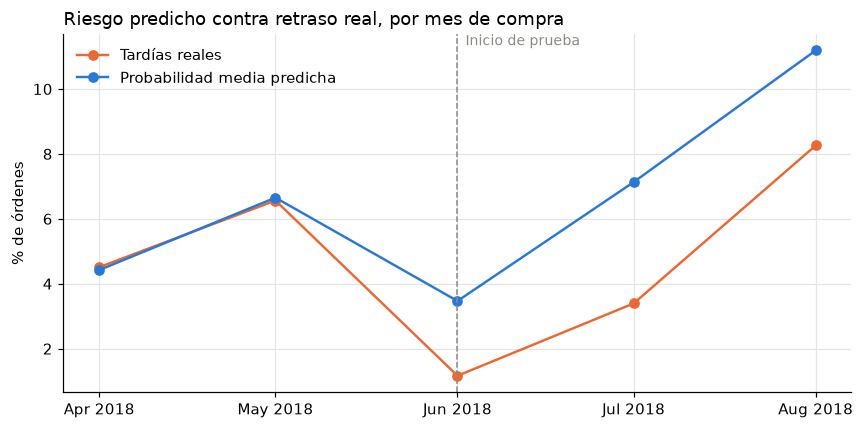

In [18]:
seguimiento = pd.concat([
    pd.DataFrame({"fecha_compra": val["fecha_compra"], "real": y_val, "predicho": prob_val_cal}),
    pd.DataFrame({"fecha_compra": test["fecha_compra"], "real": y_test, "predicho": prob_test}),
])
seguimiento["mes"] = seguimiento["fecha_compra"].dt.to_period("M").dt.to_timestamp()
mensual = seguimiento.groupby("mes")[["real", "predicho"]].mean() * 100
display(mensual.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mensual.index, mensual["real"], marker="o", color=NARANJA, label="Tardías reales")
ax.plot(mensual.index, mensual["predicho"], marker="o", color=AZUL, label="Probabilidad media predicha")
ax.axvline(pd.Timestamp(INICIO_TEST), color=GRIS, linestyle="--", linewidth=1)
ax.text(pd.Timestamp(INICIO_TEST), ax.get_ylim()[1], "  Inicio de prueba", va="top", fontsize=9, color=GRIS)
ax.set_ylabel("% de órdenes")
ax.set_title("Riesgo predicho contra retraso real, por mes de compra")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# Relación de cada variable numérica con el retraso en cada partición (AUC de la variable sola).
# Un valor por encima de 0.5 indica que valores altos se asocian con retraso, por debajo de 0.5
# lo contrario. Si la variable cruza 0.5 entre particiones, su relación con el retraso cambió.
filas = []
for variable in ["dias_prometidos", "holgura_ruta", "distancia_km", "ruta_dias_entrega_prom",
                 "ruta_tasa_retraso", "vendedor_tasa_retraso", "tasa_retraso_reciente", "ordenes_ultimos_7d"]:
    fila = {"variable": variable}
    for nombre, df in [("train", train), ("val", val), ("test", test)]:
        valores = df[variable].fillna(df[variable].median())
        fila[f"auc_{nombre}"] = roc_auc_score(df["tarde"], valores)
    filas.append(fila)
pd.DataFrame(filas).round(3)

,variable,auc_train,auc_val,auc_test
0,dias_prometidos,0.489,0.446,0.248
1,holgura_ruta,0.381,0.296,0.217
2,distancia_km,0.588,0.646,0.408
3,ruta_dias_entrega_prom,0.657,0.649,0.372
4,ruta_tasa_retraso,0.664,0.640,0.437
5,vendedor_tasa_retraso,0.608,0.544,0.488
6,tasa_retraso_reciente,0.601,0.441,0.426
7,ordenes_ultimos_7d,0.678,0.599,0.655


La caída en prueba no es un error del pipeline sino un cambio en cómo funciona la operación. Hay cuatro cosas que se ven en los datos.

La tasa de retraso bajó mucho. Entre junio y agosto de 2018 los tiempos de entrega fueron los más cortos de todo el dataset. Un modelo que aprendió con 8 % de retrasos y se calibró con 5.5 % sobreestima el riesgo cuando la realidad es 3.8 %, y el umbral que era bueno en validación deja de serlo.

También cambió la política de promesas. En julio y agosto Olist acortó el plazo prometido. Eso se ve en la tabla anterior: la distancia y el tiempo típico de la ruta, que en entrenamiento y validación se asociaban con más retraso, en prueba se asocian con menos, porque a las rutas largas se les siguió prometiendo bastante tiempo y el retraso se concentró en órdenes cortas con promesas muy ajustadas. En cambio, los días prometidos y la holgura de la ruta mantienen la misma dirección en las tres particiones (menos días o menos holgura, más retraso) y en prueba se vuelven las variables más fuertes.

Las variables de contexto reciente también se desajustan. Al inicio de prueba la tasa de retraso reciente todavía arrastra el paro de camioneros de mayo, así que el modelo ve una operación más riesgosa de lo que fue.

Por último está la censura. Las órdenes de prueba que no se habían entregado al cierre del dataset no aparecen, y es probable que varias de ellas fueran tardías. Parte de la caída de la tasa de retraso en prueba puede ser efecto de esto.

## 11. Conclusiones

El modelo elegido es una regresión logística calibrada, con variables construidas en SQL que solo usan información disponible al aprobar la orden. En validación ordena bien las órdenes por riesgo (PR-AUC cerca de tres veces la del azar) y con el umbral de costo mínimo, que coincide con el teórico de 0.2, ahorra un poco frente a no avisar nunca. En prueba la capacidad de ordenar se mantiene por encima del azar, pero el cambio en la tasa de retraso y en la política de promesas hace que el umbral y la calibración queden desactualizados.

Para operar esto como una alerta diaria haría falta recalibrar el modelo con frecuencia usando las entregas más recientes, revisar el umbral cada mes y vigilar la tasa de retraso real contra la predicha, como en el gráfico de la sección 10. Si la diferencia crece, es señal de reentrenar. También vale la pena darle más peso a las variables que se mantuvieron estables, como los días prometidos y la holgura de la ruta. Como trabajo futuro quedan reentrenar con los datos de validación antes de pasar a producción y probar matrices de costos acordadas con el área de servicio al cliente.

In [20]:
con.close()